# Violin Plot: Do the Reasons Students Give Match How Much They Use AI?

## What we suspect

We want to understand the reasons some students use AI more than others. Through some of the survey questions, we were able to get both **internal** and **external** reasons that keep students from using AI (e.g. "I want to learn the material myself" is internal, while "my class rules don't allow it" is external).

We expect that students who say a reason holds them back more will use AI less. In particular, we suspect that students who genuinely want to learn the material will drop off in reliance score as we move from "not at all / a little" to "a lot." We want to see whether that holds for **both** kinds of reasons, internal and external, or only some of them. If class rules work the way personal reasons do, those students should drop off as well.

*Note:* this is self-reported survey data. We take students' answers at face value; we can't verify them.

## [SETUP] Imports and data

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

df = pd.read_csv("../../data/uncleaned_data.csv")
df.shape

(86, 175)

## [DATA CLEANING] AI-reliance score and groups

**Features:**
- **CA–CH:** "How often do you use AI for the following: [task]" questions. For building the AI-reliance score (y-axis).
- **DE, DG, DH:** "How much does each of these keep you from using AI?" questions (x-axis)

Below are the 3 groups of students that we will divide into plots:

| Short name | Column | Group | Comes from |
|---|---|---|---|
| `learn_myself` | DE | I want to learn the material myself | student |
| `no_trust` | DG | I don't trust its answers | student |
| `rules` | DH | My class rules don't allow it | class |

Within each of these groups the x-axis will contain not at all/a little, somewhat, and alot.

**AI-reliance score:** each of the 8 answers is converted to a number (I don't use AI for this = 0, rarely = 1, sometimes = 2, very often = 3, prefer not to answer = missing), then averaged per student. A score of 0 means the student never uses AI for any of these tasks; 3 means they use it very often for all of them. Students who answered fewer than 6 of the 8 are left unscored, since they mostly skipped the section.

**Groups:** "Not at all" is merged with "A little" because "Not at all" is too small on its own (e.g. 6 students for DE).

In [ ]:
# takes in the question string as parameter, list comprehension to loop through columns to find a match, asserts there is only one match, return the match.
def find_col(text) -> str:
    matches = [c for c in df.columns if text in c]
    assert len(matches) == 1, f"{text!r} matched {len(matches)} columns"
    return matches[0]

# list comprehension for ai use columns that will help calculate the ai-reliance score
ai_use_cols = [c for c in df.columns if c.startswith("How often do you use AI for the following:")]

# storing the columns in a dict
group_cols = {
    "learn_myself": find_col("[I want to learn the material myself]"),
    "no_trust":     find_col("trust its answers]"),  # the apostrophe in "don't" is a broken character in the data
    "rules":        find_col("[My class rules don't allow it]"),
}

print(len(ai_use_cols), "AI-use columns:")
for c in ai_use_cols:
    print("  ", c.split("[")[-1].rstrip("]"))

# df.head()

8 AI-use columns:
   Reviewing Lecture slides
   Completing coding assignments
   Completing homework for STEM related subjects (ex. Math or Physics)
   Completing writing based assignments (ex. English or Psychology)
   Reviewing tests to understand how you made a calculation mistake (ex. Math or Physics
   Reviewing written works or tests to understand where you made a mistake or can improve (ex. English or Psychology)
   Asking Questions/Clarifying
   Asking for definitions


In [ ]:

def ai_use_to_num(answer):
    """
    Convert one 'How often do you use AI for...' answer to 0-3.
    """
    if pd.isna(answer):
        return np.nan
    answer = answer.lower()
    if "very often" in answer:
        return 3
    if "sometimes" in answer:
        return 2
    if "rarely" in answer:
        return 1
    if "don" in answer:  # "I don't use AI for this" (broken apostrophe, so match on part of it)
        return 0
    return np.nan        # "Prefer not to answer"

# convert that column answers into values through the function. here we take the answers to the ai use questions to obtain values for those answers
ai_use = df[ai_use_cols].map(ai_use_to_num) # (86, 8)

# create a new df that contains the shortened names as columns and the Series of each answer
violin_df = pd.DataFrame({name: df[col] for name, col in group_cols.items()}) # (86, 3)
violin_df["reliance_score"] = ai_use.mean(axis=1) # (86, 4)
# for students who had less than six answers, remove the reliance score
violin_df.loc[ai_use.notna().sum(axis=1) < 6, "reliance_score"] = np.nan

# print("Students with a reliance score:", violin_df["reliance_score"].notna().sum(), "of", len(violin_df))
violin_df.shape
# ai_use.shape

(86, 4)

In [ ]:
GROUP_ORDER = ["Not at all / A little", "Somewhat", "A lot"]
merge_low = {"Not at all": "Not at all / A little", "A little": "Not at all / A little"}

for name in group_cols:
    violin_df[name + "_group"] = pd.Categorical(
        violin_df[name].replace(merge_low), categories=GROUP_ORDER, ordered=True
    )

violin_df.head()

,learn_myself,no_trust,rules,reliance_score,learn_myself_group,no_trust_group,rules_group
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Somewhat,Not at all,A lot,1.875,Somewhat,Not at all / A little,A lot
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Somewhat,Somewhat,Somewhat,2.000,Somewhat,Somewhat,Somewhat
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## [VISUALIZATION] Our analysis

To compare these reasons, we use the AI-reliance score (0–3) built above. For each reason we have a panel, and within each panel, students are split into groups based on how much they say that reason holds them back. Each group gets its own violin showing the spread of their AI-reliance scores. This way we can see whether what students say holds them back lines up with how much they use AI.

**How to read it:**
- Every student appears once in every panel, in whichever group matches their answer to that panel's question.
- The height of a violin is the AI-reliance score. Wide parts are where many students' scores fall; thin parts are where few do.
- The dashed lines mark the median and the middle half of each group; each dot is one student.
- If the violins **step down** from left to right, students who feel that reason more strongly use AI less. If they **stay level**, the reason doesn't line up with a difference in AI use.

In [5]:
# (column short name, panel title, internal/external)
PANELS = [
    ("learn_myself", "\"I want to learn the material myself\"", "internal"),
    ("no_trust",     "\"I don't trust its answers\"",          "internal"),
    ("rules",        "\"My class rules don't allow it\"",      "external"),
]

# Group sizes and medians behind the plot
violin_summary = pd.concat(
    {
        name: violin_df.dropna(subset=["reliance_score", name + "_group"])
                       .groupby(name + "_group", observed=False)["reliance_score"]
                       .agg(n="count", median="median")
                       .round(2)
        for name, _, _ in PANELS
    },
    axis=1,
)
violin_summary

learn_myself        no_trust        rules       
                                 n median        n median     n median
Not at all / A little           22   2.31       38   2.06    24   1.88
Somewhat                        23   1.75       31   1.75    25   1.75
A lot                           32   1.56        8   0.88    27   1.75

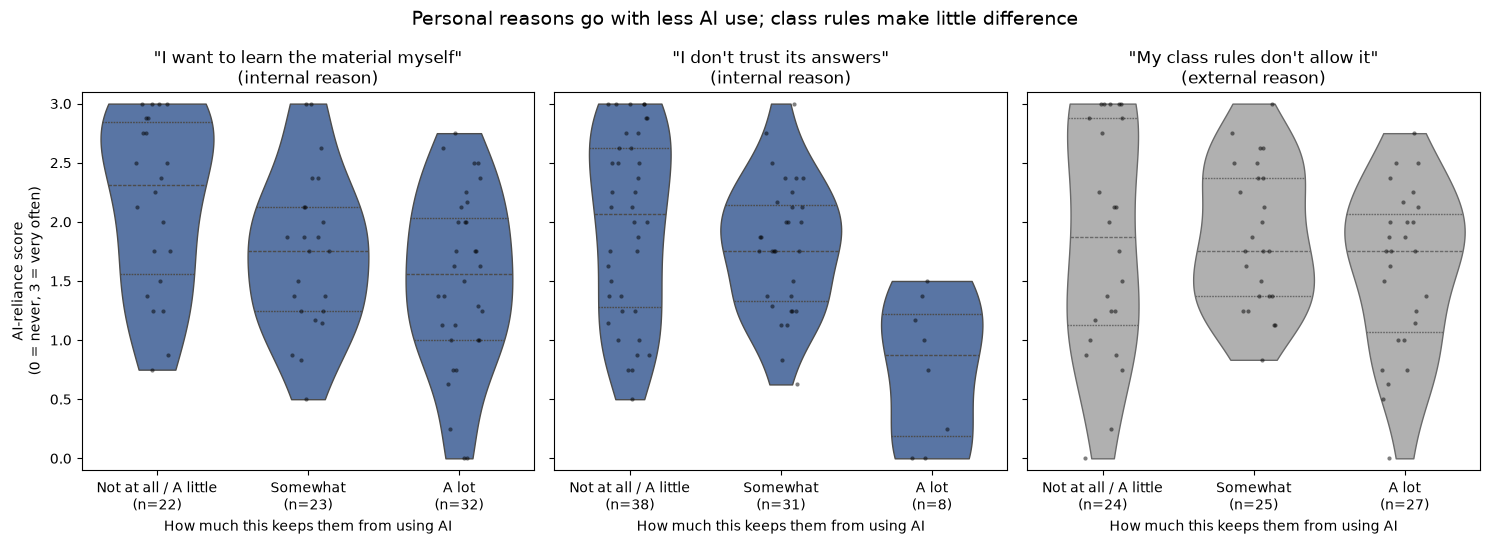

In [6]:
COLORS = {"internal": "#4C72B0", "external": "#B0B0B0"}

fig, axes = plt.subplots(1, 3, figsize=(15, 5.5), sharey=True)

for ax, (name, title, kind) in zip(axes, PANELS):
    group_col = name + "_group"
    panel = violin_df.dropna(subset=["reliance_score", group_col])  # drop blanks for THIS panel only

    sns.violinplot(data=panel, x=group_col, y="reliance_score", order=GROUP_ORDER,
                   cut=0, inner="quartile", color=COLORS[kind], linewidth=1, ax=ax)
    sns.stripplot(data=panel, x=group_col, y="reliance_score", order=GROUP_ORDER,
                  color="black", size=3, alpha=0.5, jitter=0.15, ax=ax)

    counts = panel[group_col].value_counts()
    ax.set_xticks(range(len(GROUP_ORDER)))
    ax.set_xticklabels([f"{g}\n(n={counts[g]})" for g in GROUP_ORDER])
    ax.set_title(f"{title}\n({kind} reason)")
    ax.set_xlabel("How much this keeps them from using AI")
    ax.set_ylabel("")

axes[0].set_ylabel("AI-reliance score\n(0 = never, 3 = very often)")
axes[0].set_ylim(-0.1, 3.1)
fig.suptitle("Personal reasons go with less AI use; class rules make little difference", fontsize=14)
fig.tight_layout()
plt.show()

## [VISUALIZATION] Findings

- **"I want to learn the material myself" (internal):** the violins step down. Students for whom this matters little have a median reliance score of **2.31**, compared with **1.75** for "somewhat" and **1.56** for "a lot."
- **"I don't trust its answers" (internal):** the same downward pattern, and the steepest drop: **2.06 → 1.75 → 0.88**. The "a lot" group is small (n = 8), but almost all of them sit near the bottom of the scale.
- **"My class rules don't allow it" (external):** unlike the two internal reasons, the violins stay roughly level (**1.88 → 1.75 → 1.75**). Students who say class rules hold them back "a lot" use AI about as much as students who say they don't.
- **Overlap:** in every panel the violins overlap a lot. Even the students most committed to learning the material themselves still have a median score of about 1.5 (between "rarely" and "sometimes").

## [HYPOTHESIS] Statement and test

**Hypothesis:** Students who say "I want to learn the material myself" keeps them from using AI more strongly have a lower AI-reliance score.

- **H₀:** there is no monotonic relationship between how much this reason holds a student back and their AI-reliance score (ρ = 0).
- **H₁:** the relationship is negative (ρ < 0).

**Test and justification:** Spearman rank correlation. The reason is answered on an *ordered* scale (Not at all < A little < Somewhat < A lot) rather than a true number, and the reliance score is not normally distributed, so a rank-based correlation is more appropriate than Pearson. For the test, all four original levels are used (mapped to 0–3); the merge was only for the plot. The same test is run on the other two reasons for comparison. Significance level α = 0.05.

In [7]:
DETERRENT_LEVELS = {"Not at all": 0, "A little": 1, "Somewhat": 2, "A lot": 3}

spearman_results = []
for name, title, kind in PANELS:
    d = violin_df[[name, "reliance_score"]].dropna()
    rho, p = spearmanr(d[name].map(DETERRENT_LEVELS), d["reliance_score"])
    spearman_results.append({"deterrent": title, "type": kind, "n": len(d),
                             "spearman_rho": round(rho, 3), "p_value": round(p, 4)})

pd.DataFrame(spearman_results)

,deterrent,type,n,spearman_rho,p_value
0,"""I want to learn the material myself""",internal,77,-0.359,0.0013
1,"""I don't trust its answers""",internal,77,-0.354,0.0016
2,"""My class rules don't allow it""",external,76,-0.136,0.2423


## [HYPOTHESIS] Result

| Reason | ρ | p | Result |
|---|---|---|---|
| I want to learn the material myself | −0.36 | 0.001 | significant |
| I don't trust its answers | −0.35 | 0.002 | significant |
| My class rules don't allow it | −0.14 | 0.24 | not significant |

For "I want to learn the material myself," ρ = −0.36 with p = 0.001 < 0.05, so we **reject H₀**: students who are held back more by wanting to learn the material themselves have lower AI-reliance scores. The correlation is moderate, not strong, so this reason explains part of the difference between students, not all of it.

The comparison tests match the violin plot: distrust of AI shows a similar moderate negative correlation, while class rules show no significant relationship.

*Note:* this is a correlation from a survey, so it shows association, not cause. A student who uses AI less might also come to value learning on their own more, rather than the other way around.

## Conclusion

Taking students' answers at face value, the reasons that line up with using AI less are **personal beliefs**, not rules. Students who want to learn the material themselves or don't trust AI's answers use it noticeably less, while students who say class rules hold them back use it about as much as everyone else.

This partly matches what we suspected: wanting to learn the material does go with lower AI use. But the external reason did **not** behave like the internal ones. A class rule on its own doesn't line up with a difference in how much students use AI.

Personal reasons reduce AI use but don't eliminate it: even the most committed students still use AI somewhere between "rarely" and "sometimes." So beliefs explain part of why some students use AI more than others, but not all of it.